# Energy Efficiency Dataset

Dataset structure, distributions, and relationships.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd().resolve()
project_root = cwd.parent if cwd.name == "notebooks" else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import FEATURE_COLUMNS, TARGET_COLUMNS

## Raw data

In [2]:
DATA_PATH = project_root / "data" / "raw" / "ENB2012_data.xlsx"
print(DATA_PATH)
print("Exists:", DATA_PATH.exists())

df_raw = pd.read_excel(DATA_PATH)
df_raw.head()

C:\Senior Year\ELEG405\eleg405-energy-load-prediction\data\raw\ENB2012_data.xlsx
Exists: True


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [3]:
print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())
df_raw.info()

Shape: (768, 10)
Columns: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1', 'Y2']
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [4]:
print("Missing values:")
print(df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())
df_raw.describe()

Missing values:
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y1    0
Y2    0
dtype: int64

Duplicate rows: 0


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


## Named columns and dataset shape

In [5]:
COLUMN_MAP = {
    "X1": "relative_compactness",
    "X2": "surface_area",
    "X3": "wall_area",
    "X4": "roof_area",
    "X5": "overall_height",
    "X6": "orientation",
    "X7": "glazing_area",
    "X8": "glazing_area_distribution",
    "Y1": "heating_load",
    "Y2": "cooling_load",
}

df = df_raw.rename(columns=COLUMN_MAP)
expected_columns = FEATURE_COLUMNS + TARGET_COLUMNS

print("Expected:", expected_columns)
print("Actual:  ", df.columns.tolist())
print("Match:", df.columns.tolist() == expected_columns)
df.head()

Expected: ['relative_compactness', 'surface_area', 'wall_area', 'roof_area', 'overall_height', 'orientation', 'glazing_area', 'glazing_area_distribution', 'heating_load', 'cooling_load']
Actual:   ['relative_compactness', 'surface_area', 'wall_area', 'roof_area', 'overall_height', 'orientation', 'glazing_area', 'glazing_area_distribution', 'heating_load', 'cooling_load']
Match: True


,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [6]:
X = df[FEATURE_COLUMNS]
y = df[TARGET_COLUMNS]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768, 2)


## Values and distributions

In [7]:
for column in df.columns:
    print(
        f"{column:28s} "
        f"unique={df[column].nunique():3d} "
        f"min={df[column].min()} "
        f"max={df[column].max()}"
    )

for column in df.columns:
    if df[column].nunique() <= 10:
        print(f"\n{column}")
        print(sorted(df[column].unique()))

relative_compactness         unique= 12 min=0.62 max=0.98
surface_area                 unique= 12 min=514.5 max=808.5
wall_area                    unique=  7 min=245.0 max=416.5
roof_area                    unique=  4 min=110.25 max=220.5
overall_height               unique=  2 min=3.5 max=7.0
orientation                  unique=  4 min=2 max=5
glazing_area                 unique=  4 min=0.0 max=0.4
glazing_area_distribution    unique=  6 min=0 max=5
heating_load                 unique=587 min=6.01 max=43.1
cooling_load                 unique=636 min=10.9 max=48.03

wall_area
[np.float64(245.0), np.float64(269.5), np.float64(294.0), np.float64(318.5), np.float64(343.0), np.float64(367.5), np.float64(416.5)]

roof_area
[np.float64(110.25), np.float64(122.5), np.float64(147.0), np.float64(220.5)]

overall_height
[np.float64(3.5), np.float64(7.0)]

orientation
[np.int64(2), np.int64(3), np.int64(4), np.int64(5)]

glazing_area
[np.float64(0.0), np.float64(0.1), np.float64(0.25), np.float64

In [8]:
df[TARGET_COLUMNS].describe()

,heating_load,cooling_load
count,768.000000,768.000000
mean,22.307195,24.587760
std,10.090204,9.513306
min,6.010000,10.900000
25%,12.992500,15.620000
50%,18.950000,22.080000
75%,31.667500,33.132500
max,43.100000,48.030000


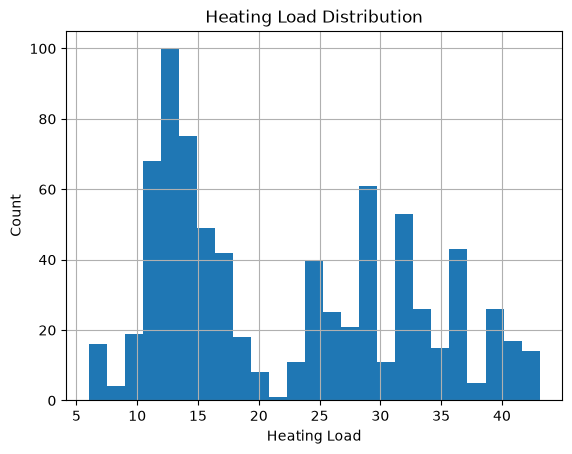

In [9]:
df["heating_load"].hist(bins=25)
plt.xlabel("Heating Load")
plt.ylabel("Count")
plt.title("Heating Load Distribution")
plt.show()

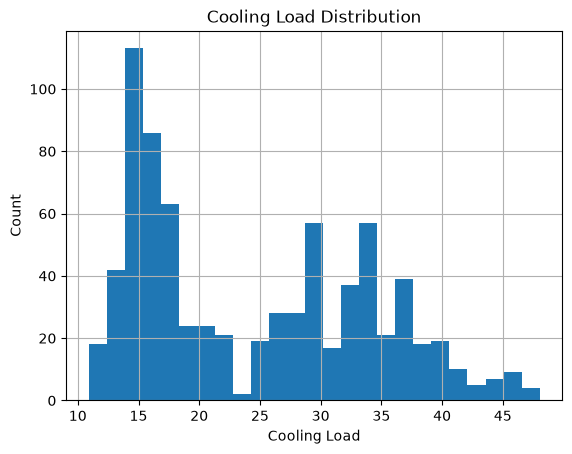

In [10]:
df["cooling_load"].hist(bins=25)
plt.xlabel("Cooling Load")
plt.ylabel("Count")
plt.title("Cooling Load Distribution")
plt.show()

## Relationships

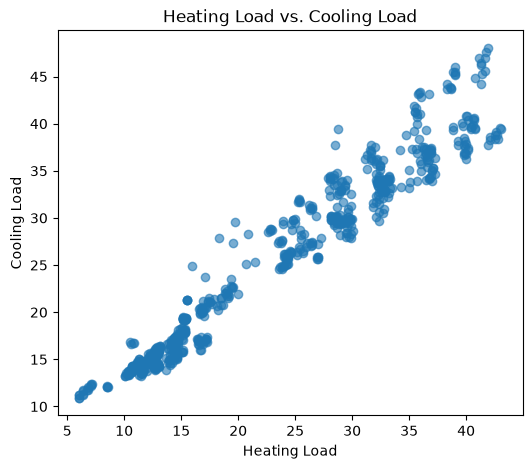

,heating_load,cooling_load
heating_load,1.000000,0.975862
cooling_load,0.975862,1.000000


In [11]:
plt.figure(figsize=(6, 5))
plt.scatter(df["heating_load"], df["cooling_load"], alpha=0.6)
plt.xlabel("Heating Load")
plt.ylabel("Cooling Load")
plt.title("Heating Load vs. Cooling Load")
plt.show()

df[["heating_load", "cooling_load"]].corr()

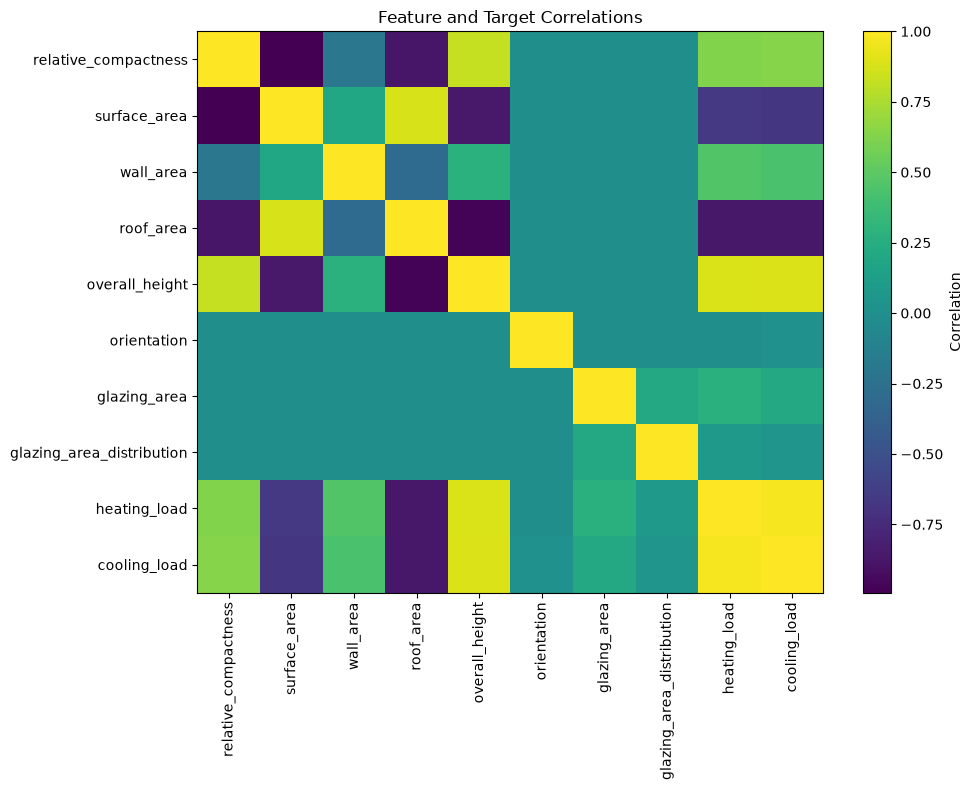

,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
relative_compactness,1.000000e+00,-9.919015e-01,-2.037817e-01,-8.688234e-01,8.277473e-01,4.678592e-17,-2.960552e-15,-7.107006e-16,0.622272,0.634339
surface_area,-9.919015e-01,1.000000e+00,1.955016e-01,8.807195e-01,-8.581477e-01,-3.459372e-17,3.636925e-15,2.438409e-15,-0.658120,-0.672999
wall_area,-2.037817e-01,1.955016e-01,1.000000e+00,-2.923165e-01,2.809757e-01,-2.429499e-17,-8.567455e-17,2.067384e-16,0.455671,0.427117
roof_area,-8.688234e-01,8.807195e-01,-2.923165e-01,1.000000e+00,-9.725122e-01,-5.830058e-17,-1.759011e-15,-1.078071e-15,-0.861828,-0.862547
overall_height,8.277473e-01,-8.581477e-01,2.809757e-01,-9.725122e-01,1.000000e+00,4.492205e-17,1.489134e-17,-2.920613e-17,0.889430,0.895785
orientation,4.678592e-17,-3.459372e-17,-2.429499e-17,-5.830058e-17,4.492205e-17,1.000000e+00,-9.406007e-16,-2.549352e-16,-0.002587,0.014290
glazing_area,-2.960552e-15,3.636925e-15,-8.567455e-17,-1.759011e-15,1.489134e-17,-9.406007e-16,1.000000e+00,2.129642e-01,0.269842,0.207505
glazing_area_distribution,-7.107006e-16,2.438409e-15,2.067384e-16,-1.078071e-15,-2.920613e-17,-2.549352e-16,2.129642e-01,1.000000e+00,0.087368,0.050525
heating_load,6.222719e-01,-6.581199e-01,4.556714e-01,-8.618281e-01,8.894305e-01,-2.586763e-03,2.698417e-01,8.736846e-02,1.000000,0.975862
cooling_load,6.343391e-01,-6.729989e-01,4.271170e-01,-8.625466e-01,8.957852e-01,1.428960e-02,2.075050e-01,5.052512e-02,0.975862,1.000000


In [12]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90,
)
plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
)
plt.title("Feature and Target Correlations")
plt.tight_layout()
plt.show()

correlation_matrix

## Development/test split

The test set is reserved for final evaluation.

In [13]:
from src.data import create_dev_test_split, load_data

df_shared = load_data()
print("Shared data shape:", df_shared.shape)
print("Columns match:", df_shared.columns.tolist() == expected_columns)

X_dev, X_test, y_dev, y_test = create_dev_test_split(df_shared)
print("X development:", X_dev.shape)
print("X test:", X_test.shape)
print("y development:", y_dev.shape)
print("y test:", y_test.shape)

Shared data shape: (768, 10)
Columns match: True
X development: (614, 8)
X test: (154, 8)
y development: (614, 2)
y test: (154, 2)
